# IP_GFP + GV_GFP UMAPs for prioritized programs and Cdh5

This notebook replaces the discrete dominant-program plot with **continuous usage UMAPs**.

It produces:

1. a four-panel UMAP for **P15, P9, P6, and P12**;
2. one individual UMAP for each program;
3. a UMAP of normalized **Cdh5** expression;
4. a five-panel overview containing the four programs plus Cdh5;
5. a cell-level CSV containing UMAP coordinates, all four program usages, and Cdh5 expression.

No program labels are placed over the cells. Panel titles appear above each axis.

Program color represents continuous cNMF usage in every cell, not whether the program is globally dominant. Values above the configured quantile are clipped only for visualization; exported CSV values are unmodified.

In [3]:
# Set thread limits before importing NumPy/SciPy.
import os

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(variable, "1")

os.environ.setdefault("PYTHONNOUSERSITE", "1")


'1'

In [4]:
from __future__ import annotations

from pathlib import Path
import re
import sys
import warnings

import anndata as ad
from IPython.display import display
import matplotlib as mpl
import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import pandas as pd
import scipy.sparse as sp

warnings.filterwarnings("ignore")

# Keep text and plotted points editable in PDF/SVG.
mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 8,
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)

print("Python:", sys.version.split()[0])


Python: 3.11.14


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


## Configuration

In [5]:
# ---------------------------------------------------------------------
# Selected K30 / density-threshold-2.0 model
# ---------------------------------------------------------------------
BASE = Path(
    "/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/"
    "analysis/250507_ePAH1_NovaSeq/CRISPR_count/"
    "IP_GV_unified_sceptre_cnmf_no_celltype"
)

RUN_NAME = "IP_GV_skcnmf_K30_dt2_0_n100"
RUN_ROOT = BASE / "PerturbNMF" / "results" / RUN_NAME

EXPECTED_H5MU_PATH = (
    RUN_ROOT
    / "Inference"
    / "adata"
    / "cNMF_30_2_0.h5mu"
)

if EXPECTED_H5MU_PATH.exists():
    H5MU_PATH = EXPECTED_H5MU_PATH
else:
    candidates = sorted(
        (BASE / "PerturbNMF").glob(
            "**/Inference/adata/cNMF_30_2_0.h5mu"
        )
    )
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Expected {EXPECTED_H5MU_PATH}, and auto-discovery found "
            f"{len(candidates)} candidates: {candidates}"
        )
    H5MU_PATH = candidates[0]
    RUN_ROOT = H5MU_PATH.parents[2]

# Fallback UMAP source if X_umap is not retained in the compiled H5MU.
PREPARED_H5AD_PATH = (
    BASE
    / "PerturbNMF"
    / "input"
    / "IP_GFP_GV_GFP_guide_positive_PerturbNMF_input.h5ad"
)

OUTPUT_DIR = (
    RUN_ROOT
    / "Evaluation"
    / "30_2_0"
    / "selected_program_umap"
    / "continuous_usage_and_Cdh5"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Programs and labels
# ---------------------------------------------------------------------
SELECTED_PROGRAMS = [15, 9, 6, 12]

PROGRAM_LABELS = {
    15: "Homeostatic EC",
    9: "Angiogenic migration",
    6: "Inflammatory adhesion",
    12: "sGC-cGMP remodeling",
}

MARKER_GENE = "Cdh5"

# ---------------------------------------------------------------------
# Plot settings
# ---------------------------------------------------------------------
PROGRAM_CMAP = "viridis"
GENE_CMAP = "magma"

# The top 1% is clipped in the plots so a few extreme cells do not compress
# the color range. Raw values remain unchanged in the exported CSV.
COLOR_CLIP_QUANTILE = 0.99

BACKGROUND_COLOR = "#DDE1E6"
BACKGROUND_ALPHA = 0.55
BACKGROUND_SIZE = 5.0

POINT_SIZE = 8.0
POINT_ALPHA = 0.95
RASTERIZE_POINTS = False  # False keeps points vector-editable in PDF/SVG.

PROGRAM_FIGSIZE = (8.6, 7.4)
INDIVIDUAL_FIGSIZE = (4.6, 4.1)
GENE_FIGSIZE = (4.8, 4.2)
OVERVIEW_FIGSIZE = (12.0, 7.6)

OUTPUT_STEM = "IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5"

print("H5MU:", H5MU_PATH)
print("Prepared H5AD fallback:", PREPARED_H5AD_PATH)
print("Output directory:", OUTPUT_DIR)


H5MU: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Inference/adata/cNMF_30_2_0.h5mu
Prepared H5AD fallback: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/input/IP_GFP_GV_GFP_guide_positive_PerturbNMF_input.h5ad
Output directory: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5


## Helper functions

In [6]:
def dense_array(matrix) -> np.ndarray:
    if sp.issparse(matrix):
        return matrix.toarray()
    if hasattr(matrix, "toarray"):
        return matrix.toarray()
    return np.asarray(matrix)


def infer_program_ids(var_names: pd.Index) -> list[int]:
    """Infer one-based program numbers from cNMF variable names."""
    parsed = []
    for value in var_names.astype(str):
        match = re.search(r"(\d+)$", value)
        parsed.append(int(match.group(1)) if match else None)

    n_programs = len(var_names)

    if all(value is not None for value in parsed):
        parsed_int = [int(value) for value in parsed]
        if len(set(parsed_int)) == n_programs:
            if set(parsed_int) == set(range(n_programs)):
                return [value + 1 for value in parsed_int]
            return parsed_int

    print(
        "Could not infer unique program IDs from var_names; "
        "using column order as P1..PK."
    )
    return list(range(1, n_programs + 1))


def align_obsm_to_target(
    source,
    target_obs_names: pd.Index,
    key: str = "X_umap",
) -> np.ndarray:
    if key not in source.obsm:
        raise KeyError(f"{key!r} is absent from source.obsm.")

    source_index = pd.Index(source.obs_names)
    target_index = pd.Index(target_obs_names)

    if not source_index.is_unique or not target_index.is_unique:
        raise ValueError("Cell indexes must be unique.")

    missing = target_index.difference(source_index)
    if len(missing):
        raise ValueError(
            f"{len(missing)} target cells are absent from the UMAP source. "
            f"Examples: {missing[:10].tolist()}"
        )

    positions = source_index.get_indexer(target_index)
    coordinates = np.asarray(source.obsm[key])[positions, :2]

    if coordinates.shape != (len(target_index), 2):
        raise ValueError(
            f"Aligned UMAP has unexpected shape {coordinates.shape}."
        )
    return coordinates


def resolve_umap(
    *,
    mdata,
    cnmf,
    rna,
    prepared_h5ad_path: Path,
) -> tuple[np.ndarray, str]:
    if "X_umap" in cnmf.obsm:
        return (
            align_obsm_to_target(
                cnmf,
                pd.Index(cnmf.obs_names),
                "X_umap",
            ),
            "cNMF.obsm['X_umap']",
        )

    if "X_umap" in rna.obsm:
        return (
            align_obsm_to_target(
                rna,
                pd.Index(cnmf.obs_names),
                "X_umap",
            ),
            "rna.obsm['X_umap']",
        )

    if "X_umap" in mdata.obsm:
        coordinates = np.asarray(mdata.obsm["X_umap"])
        if coordinates.shape[0] != cnmf.n_obs:
            raise ValueError(
                "MuData X_umap does not have the expected number of cells."
            )
        return coordinates[:, :2], "mdata.obsm['X_umap']"

    if not prepared_h5ad_path.exists():
        raise FileNotFoundError(
            "No X_umap was found in the H5MU and the prepared H5AD "
            f"does not exist: {prepared_h5ad_path}"
        )

    prepared = ad.read_h5ad(prepared_h5ad_path, backed="r")
    try:
        coordinates = align_obsm_to_target(
            prepared,
            pd.Index(cnmf.obs_names),
            "X_umap",
        )
    finally:
        prepared.file.close()

    return coordinates, str(prepared_h5ad_path)


def matrix_is_integer_like(
    matrix,
    tolerance: float = 1e-3,
    maximum_values: int = 200_000,
) -> bool:
    if sp.issparse(matrix):
        values = np.asarray(matrix.data)
    else:
        values = np.asarray(matrix).ravel()

    values = values[np.isfinite(values)]
    if values.size == 0:
        return True

    if values.size > maximum_values:
        positions = np.linspace(
            0,
            values.size - 1,
            maximum_values,
            dtype=int,
        )
        values = values[positions]

    if values.min() < 0:
        return False

    return bool(
        np.max(np.abs(values - np.rint(values))) <= tolerance
    )


def resolve_expression_source(adata):
    """Return matrix, var table, var names, source name, and count status."""
    candidates = []

    for layer_name in ["counts", "raw_counts", "count"]:
        if layer_name in adata.layers:
            candidates.append(
                (
                    adata.layers[layer_name],
                    adata.var,
                    pd.Index(adata.var_names),
                    f"rna.layers[{layer_name!r}]",
                )
            )

    candidates.append(
        (
            adata.X,
            adata.var,
            pd.Index(adata.var_names),
            "rna.X",
        )
    )

    if adata.raw is not None:
        candidates.append(
            (
                adata.raw.X,
                adata.raw.var,
                pd.Index(adata.raw.var_names),
                "rna.raw.X",
            )
        )

    for matrix, var, var_names, source_name in candidates:
        if matrix_is_integer_like(matrix):
            return matrix, var, var_names, source_name, True

    matrix, var, var_names, source_name = candidates[0]
    return matrix, var, var_names, source_name, False


def find_gene_columns(
    var: pd.DataFrame,
    var_names: pd.Index,
    gene: str,
) -> list[int]:
    target = gene.strip().upper()
    candidate_series = []

    for column in [
        "symbol",
        "feature_name",
        "gene_symbol",
        "gene_name",
    ]:
        if column in var.columns:
            candidate_series.append(var[column].astype(str))

    candidate_series.append(
        pd.Series(var_names.astype(str), index=var_names)
    )

    matched = set()
    for series in candidate_series:
        values = series.astype(str).str.strip().str.upper().to_numpy()
        matched.update(np.flatnonzero(values == target).tolist())

    return sorted(matched)


def extract_gene_expression(
    adata,
    gene: str,
) -> tuple[np.ndarray, str, list[str]]:
    matrix, var, var_names, source_name, is_counts = (
        resolve_expression_source(adata)
    )

    columns = find_gene_columns(var, var_names, gene)
    if not columns:
        raise KeyError(
            f"Could not find {gene!r} in RNA feature symbols or names."
        )

    if sp.issparse(matrix):
        gene_values = np.asarray(
            matrix[:, columns].sum(axis=1)
        ).ravel()
    else:
        gene_values = np.asarray(
            matrix[:, columns]
        ).sum(axis=1)

    if is_counts:
        if sp.issparse(matrix):
            library_size = np.asarray(
                matrix.sum(axis=1)
            ).ravel()
        else:
            library_size = np.asarray(matrix).sum(axis=1)

        normalized = np.divide(
            1e4 * gene_values,
            library_size,
            out=np.zeros_like(gene_values, dtype=float),
            where=library_size > 0,
        )
        expression = np.log1p(normalized)
        label = f"log1p normalized {gene} expression"
    else:
        expression = np.asarray(gene_values, dtype=float)
        label = f"{gene} expression from {source_name}"

    matched_features = var_names[np.asarray(columns)].astype(str).tolist()
    return expression, label, matched_features


def robust_vmax(
    values: np.ndarray,
    quantile: float = COLOR_CLIP_QUANTILE,
) -> float:
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]

    if finite.size == 0:
        return 1.0

    positive = finite[finite > 0]
    if positive.size:
        vmax = float(np.quantile(positive, quantile))
        if vmax <= 0:
            vmax = float(positive.max())
    else:
        vmax = float(np.quantile(finite, quantile))

    if not np.isfinite(vmax) or vmax <= 0:
        vmax = 1.0

    return vmax


def format_colorbar_ticks(colorbar) -> None:
    colorbar.ax.tick_params(labelsize=7, length=2)


def draw_continuous_umap(
    ax,
    coordinates: np.ndarray,
    values: np.ndarray,
    *,
    title: str,
    colorbar_label: str,
    cmap: str,
    vmax: float | None = None,
) -> None:
    values = np.asarray(values, dtype=float)

    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=BACKGROUND_SIZE,
        c=BACKGROUND_COLOR,
        alpha=BACKGROUND_ALPHA,
        linewidths=0,
        edgecolors="none",
        rasterized=RASTERIZE_POINTS,
        zorder=1,
    )

    finite_positive = np.isfinite(values) & (values > 0)
    if finite_positive.any():
        if vmax is None:
            vmax = robust_vmax(values)

        positions = np.flatnonzero(finite_positive)
        positions = positions[
            np.argsort(values[positions], kind="stable")
        ]

        clipped = np.clip(values[positions], 0, vmax)

        scatter = ax.scatter(
            coordinates[positions, 0],
            coordinates[positions, 1],
            s=POINT_SIZE,
            c=clipped,
            cmap=cmap,
            vmin=0,
            vmax=vmax,
            alpha=POINT_ALPHA,
            linewidths=0,
            edgecolors="none",
            rasterized=RASTERIZE_POINTS,
            zorder=2,
        )

        colorbar = ax.figure.colorbar(
            scatter,
            ax=ax,
            fraction=0.045,
            pad=0.02,
        )
        colorbar.set_label(
            colorbar_label,
            fontsize=7.5,
        )
        format_colorbar_ticks(colorbar)
    else:
        ax.text(
            0.5,
            0.5,
            "No positive values",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=8,
        )

    ax.set_title(title, fontsize=9, pad=5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

    for spine in ax.spines.values():
        spine.set_visible(False)


## Load the cNMF model, UMAP, continuous program usages, and Cdh5

In [7]:
if not H5MU_PATH.exists():
    raise FileNotFoundError(H5MU_PATH)

print("Loading:", H5MU_PATH)
mdata = mu.read_h5mu(H5MU_PATH)

if "cNMF" not in mdata.mod or "rna" not in mdata.mod:
    raise KeyError(
        f"Expected 'cNMF' and 'rna' modalities; found {list(mdata.mod)}"
    )

cnmf = mdata["cNMF"]
rna = mdata["rna"]

if cnmf.n_obs != rna.n_obs:
    raise ValueError("cNMF and RNA modalities have different cell counts.")
if not cnmf.obs_names.equals(rna.obs_names):
    raise ValueError("cNMF and RNA cell order differs.")

scores = dense_array(cnmf.X).astype(float)
if scores.shape != (cnmf.n_obs, cnmf.n_vars):
    raise ValueError(
        f"Unexpected cNMF usage shape {scores.shape}; "
        f"expected {(cnmf.n_obs, cnmf.n_vars)}."
    )
if not np.isfinite(scores).all():
    raise ValueError("cNMF usage matrix contains NaN or infinite values.")

# cNMF usages should be nonnegative. Clip negligible numerical negatives.
minimum_score = float(scores.min())
if minimum_score < -1e-6:
    raise ValueError(
        f"cNMF usage contains substantial negative values: {minimum_score}"
    )
scores = np.maximum(scores, 0.0)

program_ids = infer_program_ids(pd.Index(cnmf.var_names))
program_to_column = {
    program_id: column
    for column, program_id in enumerate(program_ids)
}

missing_programs = [
    program
    for program in SELECTED_PROGRAMS
    if program not in program_to_column
]
if missing_programs:
    raise ValueError(
        f"Selected programs are absent from cNMF: {missing_programs}. "
        f"Detected IDs: {program_ids}"
    )

umap_coordinates, umap_source = resolve_umap(
    mdata=mdata,
    cnmf=cnmf,
    rna=rna,
    prepared_h5ad_path=PREPARED_H5AD_PATH,
)

program_usage = {
    program: scores[:, program_to_column[program]].copy()
    for program in SELECTED_PROGRAMS
}

cdh5_expression, cdh5_label, cdh5_features = extract_gene_expression(
    rna,
    MARKER_GENE,
)

if len(cdh5_expression) != cnmf.n_obs:
    raise ValueError("Cdh5 expression vector has the wrong number of cells.")

cell_table = pd.DataFrame(
    {
        "cell_id": cnmf.obs_names.astype(str),
        "UMAP1": umap_coordinates[:, 0],
        "UMAP2": umap_coordinates[:, 1],
        **{
            f"P{program}_usage": values
            for program, values in program_usage.items()
        },
        "Cdh5_expression": cdh5_expression,
    }
)

print(mdata)
print("UMAP source:", umap_source)
print("Cdh5 source label:", cdh5_label)
print("Matched Cdh5 feature(s):", cdh5_features)

display(
    pd.DataFrame(
        {
            "program": [f"P{x}" for x in SELECTED_PROGRAMS],
            "label": [
                PROGRAM_LABELS[x]
                for x in SELECTED_PROGRAMS
            ],
            "median_usage": [
                float(np.median(program_usage[x]))
                for x in SELECTED_PROGRAMS
            ],
            "positive_cells": [
                int(np.sum(program_usage[x] > 0))
                for x in SELECTED_PROGRAMS
            ],
            "vmax_99th_percentile": [
                robust_vmax(program_usage[x])
                for x in SELECTED_PROGRAMS
            ],
        }
    )
)


Loading: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Inference/adata/cNMF_30_2_0.h5mu
MuData object with n_obs × n_vars = 4095 × 16896
  2 modalities
    rna:	4095 x 16866
      obs:	'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'sample_id', 'barcode', 'passes_rna_qc', 'raw_total_guide_umis', 'raw_n_detected_guides', 'total_guide_umis', 'n_detected_guides', 'n_assigned_guides', 'n_assigned_targets', 'assigned_guide_umis', 'assigned_guide_ids', 'assigned_targets', 'guide_assignment_status', 'has_sceptre_guide', 'sample', 'mouse'
      var:	'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id',

,program,label,median_usage,positive_cells,vmax_99th_percentile
0,P15,Homeostatic EC,0.000000,1706,0.418533
1,P9,Angiogenic migration,0.002736,2182,0.457630
2,P6,Inflammatory adhesion,0.000773,2092,0.650562
3,P12,sGC-cGMP remodeling,0.000000,2029,0.595771


## Export cell-level plotting data

In [8]:
cell_csv = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_cell_level_data.csv.gz"
)
summary_csv = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_plot_scale_summary.csv"
)

cell_table.to_csv(
    cell_csv,
    index=False,
    compression="gzip",
)

summary_rows = []
for program in SELECTED_PROGRAMS:
    values = program_usage[program]
    summary_rows.append(
        {
            "feature": f"P{program}",
            "label": PROGRAM_LABELS[program],
            "minimum": float(np.min(values)),
            "median": float(np.median(values)),
            "mean": float(np.mean(values)),
            "maximum": float(np.max(values)),
            "positive_cells": int(np.sum(values > 0)),
            "color_vmax": robust_vmax(values),
            "color_clip_quantile": COLOR_CLIP_QUANTILE,
        }
    )

summary_rows.append(
    {
        "feature": "Cdh5",
        "label": cdh5_label,
        "minimum": float(np.min(cdh5_expression)),
        "median": float(np.median(cdh5_expression)),
        "mean": float(np.mean(cdh5_expression)),
        "maximum": float(np.max(cdh5_expression)),
        "positive_cells": int(np.sum(cdh5_expression > 0)),
        "color_vmax": robust_vmax(cdh5_expression),
        "color_clip_quantile": COLOR_CLIP_QUANTILE,
    }
)

plot_summary = pd.DataFrame(summary_rows)
plot_summary.to_csv(summary_csv, index=False)

print("Cell-level CSV:", cell_csv)
print("Plot-scale summary:", summary_csv)
display(plot_summary)


Cell-level CSV: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_cell_level_data.csv.gz
Plot-scale summary: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_plot_scale_summary.csv


,feature,label,minimum,median,mean,maximum,positive_cells,color_vmax,color_clip_quantile
0,P15,Homeostatic EC,0.0,0.000000,0.010966,1.163043,1706,0.418533,0.99
1,P9,Angiogenic migration,0.0,0.002736,0.029538,0.923949,2182,0.457630,0.99
2,P6,Inflammatory adhesion,0.0,0.000773,0.045222,1.018571,2092,0.650562,0.99
3,P12,sGC-cGMP remodeling,0.0,0.000000,0.016580,1.226344,2029,0.595771,0.99
4,Cdh5,log1p normalized Cdh5 expression,0.0,2.737665,2.633596,4.270931,4040,3.500552,0.99


## Four separate continuous-usage UMAPs

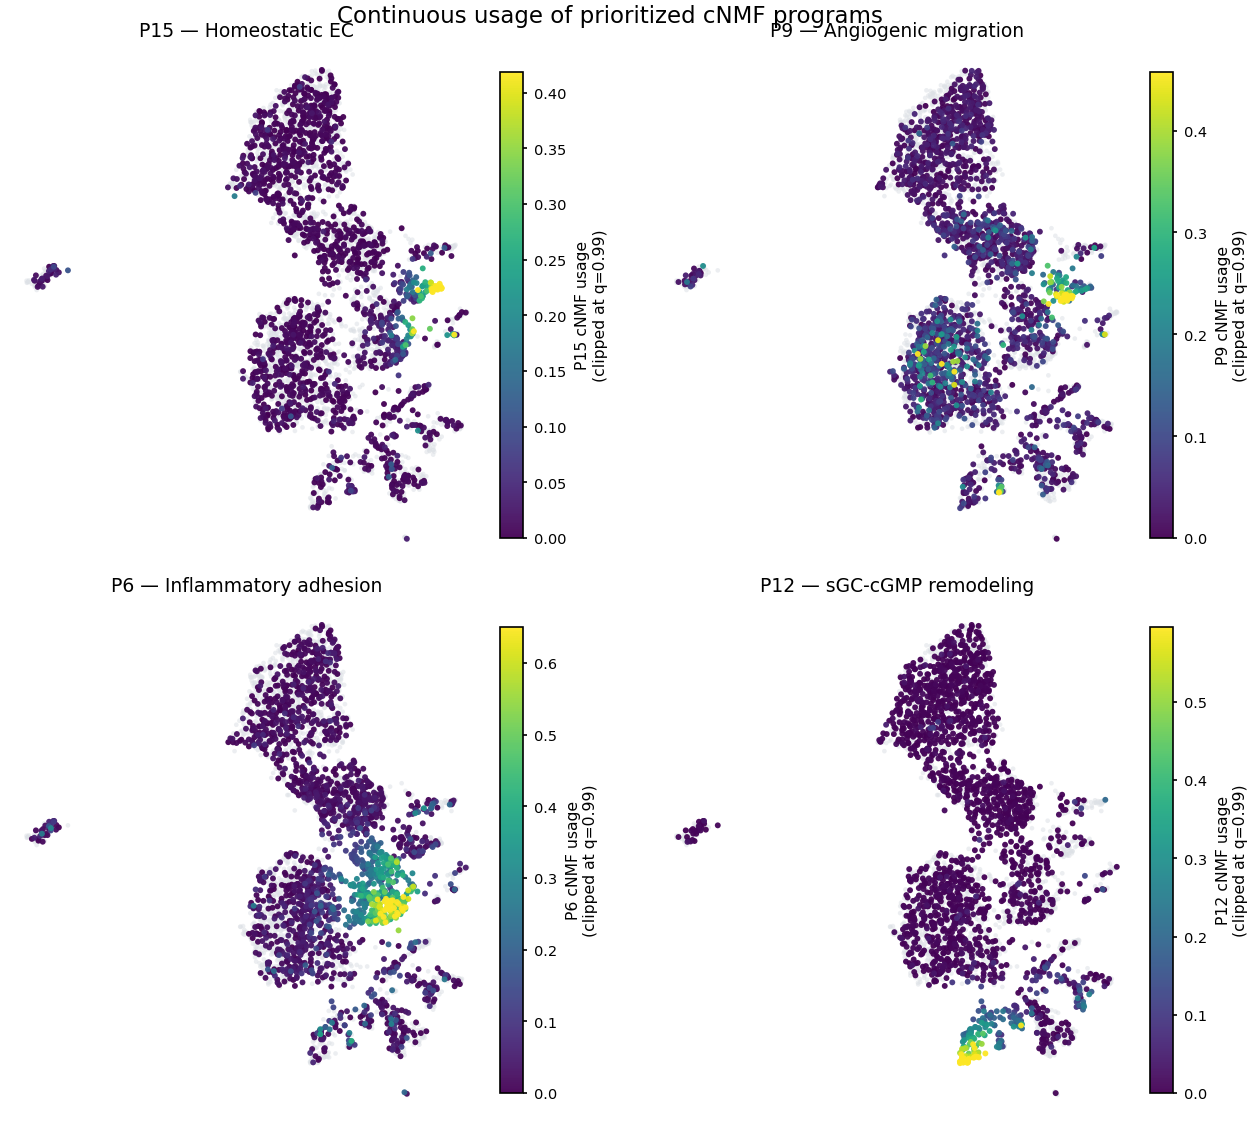

/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_four_programs.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_four_programs.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_four_programs.png


In [9]:
program_panel_pdf = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_four_programs.pdf"
)
program_panel_svg = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_four_programs.svg"
)
program_panel_png = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_four_programs.png"
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=PROGRAM_FIGSIZE,
    constrained_layout=True,
)
axes = axes.ravel()

for axis, program in zip(axes, SELECTED_PROGRAMS):
    draw_continuous_umap(
        axis,
        umap_coordinates,
        program_usage[program],
        title=f"P{program} — {PROGRAM_LABELS[program]}",
        colorbar_label=(
            f"P{program} cNMF usage\n"
            f"(clipped at q={COLOR_CLIP_QUANTILE:.2f})"
        ),
        cmap=PROGRAM_CMAP,
        vmax=robust_vmax(program_usage[program]),
    )

fig.suptitle(
    "Continuous usage of prioritized cNMF programs",
    fontsize=11,
    y=1.01,
)

fig.savefig(program_panel_pdf)
fig.savefig(program_panel_svg)
fig.savefig(program_panel_png, dpi=300)
plt.show()
plt.close(fig)

print(program_panel_pdf)
print(program_panel_svg)
print(program_panel_png)


## Save one editable UMAP file per program

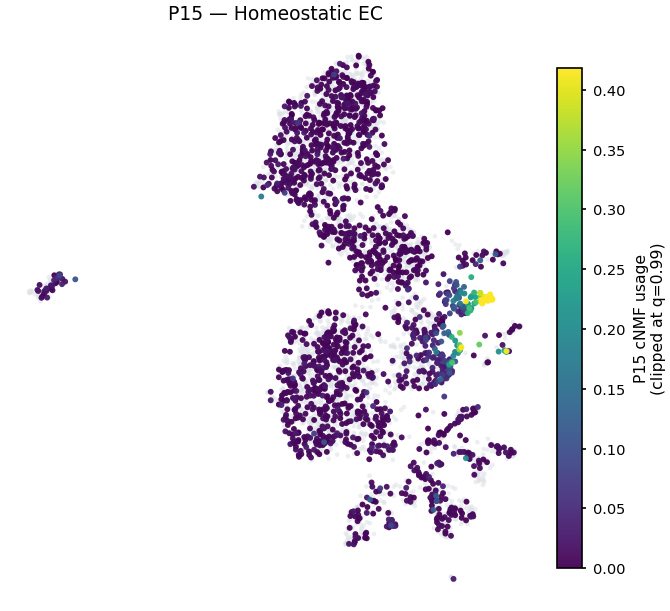

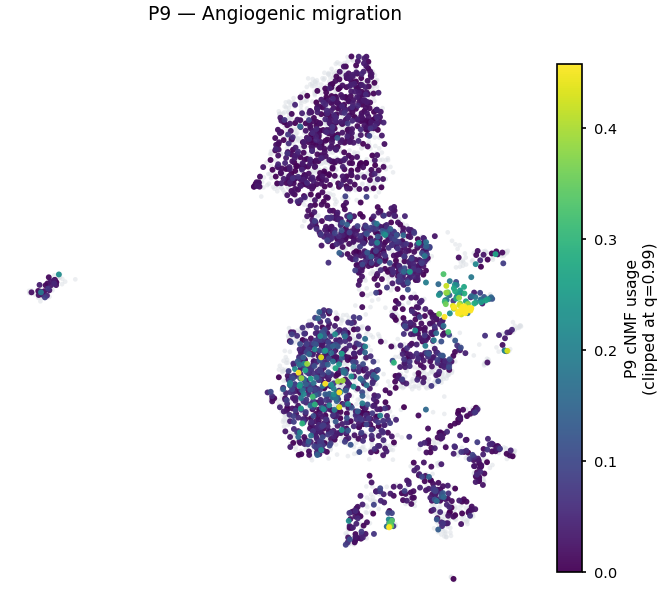

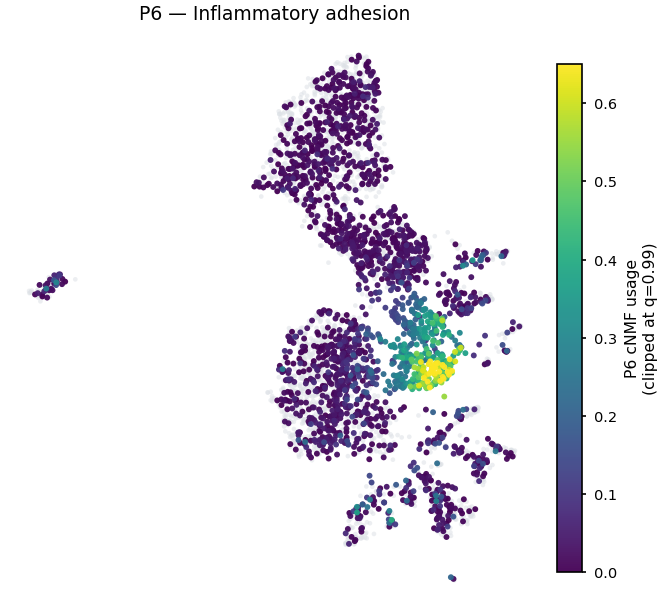

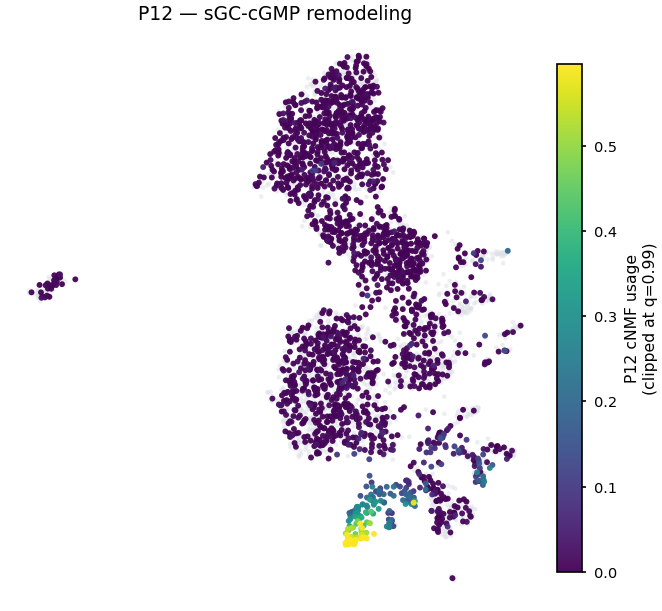

,program,pdf,svg,png
0,P15,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...
1,P9,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...
2,P6,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...
3,P12,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...,/oak/stanford/groups/engreitz/Users/tri/10xPer...


In [10]:
individual_output_rows = []

for program in SELECTED_PROGRAMS:
    fig, ax = plt.subplots(
        figsize=INDIVIDUAL_FIGSIZE,
        constrained_layout=True,
    )

    draw_continuous_umap(
        ax,
        umap_coordinates,
        program_usage[program],
        title=f"P{program} — {PROGRAM_LABELS[program]}",
        colorbar_label=(
            f"P{program} cNMF usage\n"
            f"(clipped at q={COLOR_CLIP_QUANTILE:.2f})"
        ),
        cmap=PROGRAM_CMAP,
        vmax=robust_vmax(program_usage[program]),
    )

    stem = (
        OUTPUT_DIR
        / f"IP_GV_P{program}_continuous_usage_UMAP"
    )
    pdf_path = stem.with_suffix(".pdf")
    svg_path = stem.with_suffix(".svg")
    png_path = stem.with_suffix(".png")

    fig.savefig(pdf_path)
    fig.savefig(svg_path)
    fig.savefig(png_path, dpi=300)
    plt.show()
    plt.close(fig)

    individual_output_rows.append(
        {
            "program": f"P{program}",
            "pdf": str(pdf_path),
            "svg": str(svg_path),
            "png": str(png_path),
        }
    )

display(pd.DataFrame(individual_output_rows))


## Cdh5 marker-gene UMAP

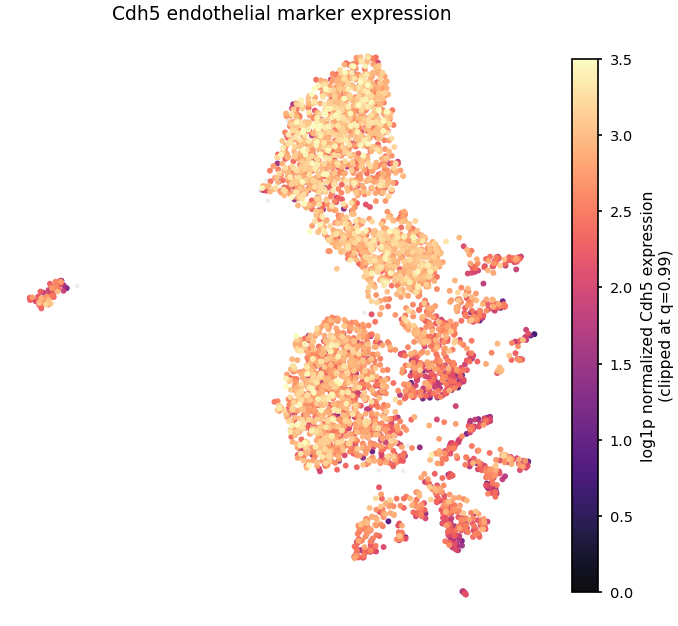

/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_Cdh5_expression_UMAP.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_Cdh5_expression_UMAP.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_Cdh5_expression_UMAP.png


In [11]:
cdh5_pdf = OUTPUT_DIR / "IP_GV_Cdh5_expression_UMAP.pdf"
cdh5_svg = OUTPUT_DIR / "IP_GV_Cdh5_expression_UMAP.svg"
cdh5_png = OUTPUT_DIR / "IP_GV_Cdh5_expression_UMAP.png"

fig, ax = plt.subplots(
    figsize=GENE_FIGSIZE,
    constrained_layout=True,
)

draw_continuous_umap(
    ax,
    umap_coordinates,
    cdh5_expression,
    title="Cdh5 endothelial marker expression",
    colorbar_label=(
        f"{cdh5_label}\n"
        f"(clipped at q={COLOR_CLIP_QUANTILE:.2f})"
    ),
    cmap=GENE_CMAP,
    vmax=robust_vmax(cdh5_expression),
)

fig.savefig(cdh5_pdf)
fig.savefig(cdh5_svg)
fig.savefig(cdh5_png, dpi=300)
plt.show()
plt.close(fig)

print(cdh5_pdf)
print(cdh5_svg)
print(cdh5_png)


## Five-panel overview: four programs plus Cdh5

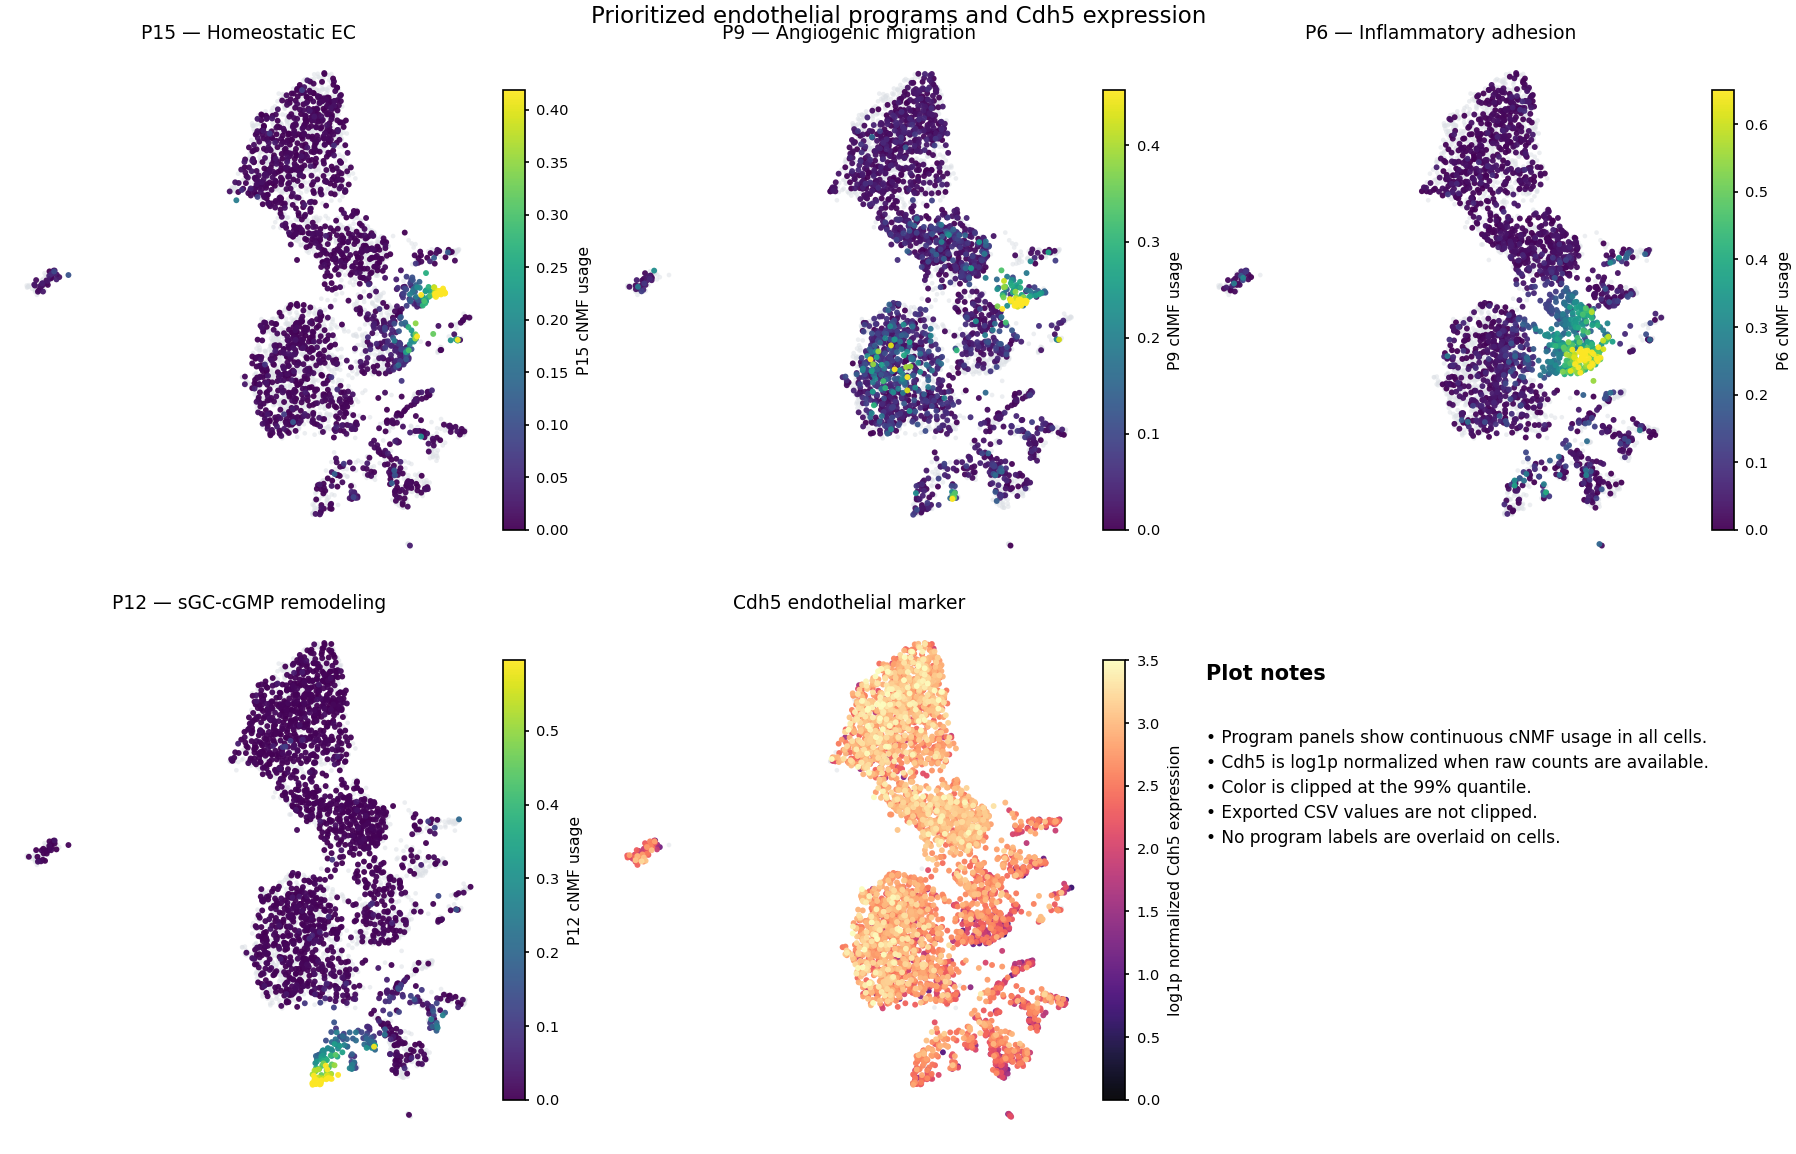

/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_five_panel_overview.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_five_panel_overview.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/IP_GV_P15_P9_P6_P12_continuous_usage_Cdh5_five_panel_overview.png


In [12]:
overview_pdf = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_five_panel_overview.pdf"
)
overview_svg = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_five_panel_overview.svg"
)
overview_png = (
    OUTPUT_DIR / f"{OUTPUT_STEM}_five_panel_overview.png"
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=OVERVIEW_FIGSIZE,
    constrained_layout=True,
)
axes = axes.ravel()

for axis, program in zip(axes[:4], SELECTED_PROGRAMS):
    draw_continuous_umap(
        axis,
        umap_coordinates,
        program_usage[program],
        title=f"P{program} — {PROGRAM_LABELS[program]}",
        colorbar_label=f"P{program} cNMF usage",
        cmap=PROGRAM_CMAP,
        vmax=robust_vmax(program_usage[program]),
    )

draw_continuous_umap(
    axes[4],
    umap_coordinates,
    cdh5_expression,
    title="Cdh5 endothelial marker",
    colorbar_label=cdh5_label,
    cmap=GENE_CMAP,
    vmax=robust_vmax(cdh5_expression),
)

axes[5].axis("off")
axes[5].text(
    0.02,
    0.90,
    "Plot notes",
    transform=axes[5].transAxes,
    fontsize=10,
    fontweight="bold",
    va="top",
)
axes[5].text(
    0.02,
    0.78,
    (
        "• Program panels show continuous cNMF usage in all cells.\n"
        "• Cdh5 is log1p normalized when raw counts are available.\n"
        f"• Color is clipped at the {COLOR_CLIP_QUANTILE:.0%} quantile.\n"
        "• Exported CSV values are not clipped.\n"
        "• No program labels are overlaid on cells."
    ),
    transform=axes[5].transAxes,
    fontsize=8.2,
    va="top",
    linespacing=1.5,
)

fig.suptitle(
    "Prioritized endothelial programs and Cdh5 expression",
    fontsize=11,
    y=1.01,
)

fig.savefig(overview_pdf)
fig.savefig(overview_svg)
fig.savefig(overview_png, dpi=300)
plt.show()
plt.close(fig)

print(overview_pdf)
print(overview_svg)
print(overview_png)


## Interpretation

The continuous program-usage UMAPs answer a different question from the original dominant-program map.

- A program can be active in many cells even when it is globally dominant in only a small subset.
- Each panel shows the full distribution of one program across all cells.
- The Cdh5 panel helps determine whether the embedding is broadly endothelial and whether the selected programs occupy Cdh5-positive regions.
- Color scales are calculated separately for each panel, so color intensity should be interpreted within a panel rather than compared numerically between panels.
- The exported CSV contains the unmodified values for quantitative comparisons.

#### UMAP annotation

RNA count source: rna.layers['counts']
Starting shape: (4095, 16866)
PCA source: cNMF.obsm['X_pca']
Number of Leiden clusters: 11


,n_cells
leiden,
0,1203
1,1185
2,589
3,348
4,200
5,176
6,122
7,94
8,68


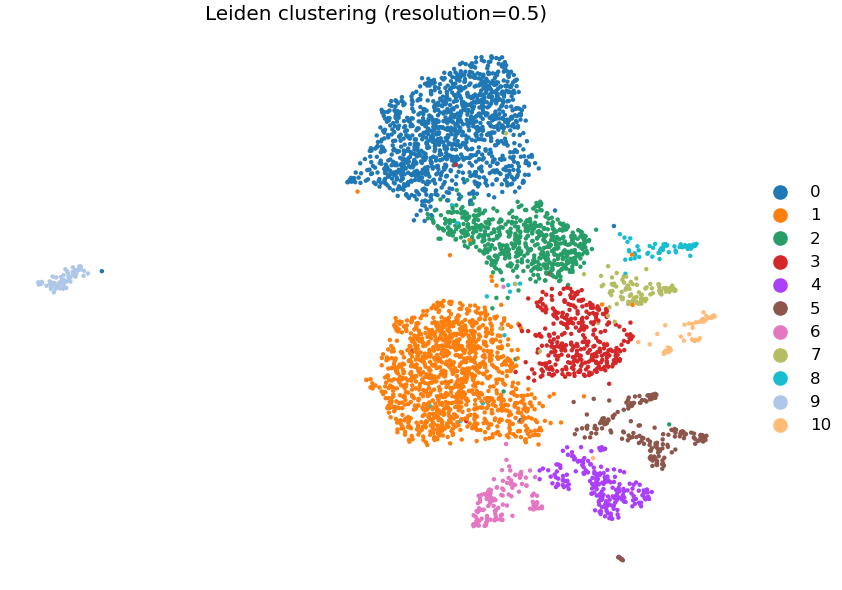


Exported files:
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_cluster_assignments.csv.gz
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_cluster_sizes.csv
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_cluster_sample_composition.csv
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/2505

,cluster,rank_within_cluster,feature_name,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference,gene_symbol,technical_gene
0,0,1,Igfbp7,44.498333,2.894991,0.000000e+00,0.000000e+00,0.996675,0.848893,Igfbp7,False
1,0,2,Car4,43.846920,3.058359,0.000000e+00,0.000000e+00,0.990856,0.708852,Car4,False
2,0,3,Emp2,42.497261,2.460400,0.000000e+00,0.000000e+00,0.992519,0.792531,Emp2,False
3,0,4,Ednrb,42.063023,3.138303,0.000000e+00,0.000000e+00,0.964256,0.440526,Ednrb,False
4,0,5,Pmp22,41.375008,2.075995,0.000000e+00,0.000000e+00,0.989194,0.886929,Pmp22,False
...,...,...,...,...,...,...,...,...,...,...,...
95,1,46,Arl15,20.950232,1.077694,1.867217e-97,2.113589e-95,0.933333,0.892784,Arl15,False
96,1,48,H2-Aa,20.582508,1.515239,3.937774e-94,4.257340e-92,0.724895,0.508247,H2-Aa,False
97,1,49,Tmsb10,20.400702,0.972727,1.648325e-92,1.716090e-90,0.972996,0.897595,Tmsb10,False
98,1,50,Hey1,20.227474,1.699971,5.610440e-91,5.700342e-89,0.613502,0.371478,Hey1,False


In [13]:
# ================================================================
# Leiden clustering + cluster-vs-rest differential expression
# ================================================================
import json

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

# ----------------------------
# Parameters
# ----------------------------
LEIDEN_RESOLUTION = 0.5
N_NEIGHBORS = 15
N_PCS = 30
N_TOP_HVG = 3000
TOP_MARKERS_PER_CLUSTER = 50
RANDOM_STATE = 14

CLUSTER_OUTPUT_DIR = OUTPUT_DIR / "leiden_clustering"
CLUSTER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------
# Resolve a raw-count matrix
# ----------------------------
def _integer_like(matrix, tolerance=1e-3):
    values = (
        np.asarray(matrix.data)
        if sp.issparse(matrix)
        else np.asarray(matrix).ravel()
    )
    values = values[np.isfinite(values)]

    if values.size == 0:
        return True

    if values.size > 200_000:
        positions = np.linspace(
            0,
            values.size - 1,
            200_000,
            dtype=int,
        )
        values = values[positions]

    return bool(
        values.min() >= 0
        and np.max(np.abs(values - np.rint(values))) <= tolerance
    )


count_candidates = []

for layer_name in ["counts", "raw_counts", "count"]:
    if layer_name in rna.layers:
        count_candidates.append(
            (
                rna.layers[layer_name],
                rna.var.copy(),
                pd.Index(rna.var_names),
                f"rna.layers[{layer_name!r}]",
            )
        )

count_candidates.append(
    (
        rna.X,
        rna.var.copy(),
        pd.Index(rna.var_names),
        "rna.X",
    )
)

if rna.raw is not None:
    count_candidates.append(
        (
            rna.raw.X,
            rna.raw.var.copy(),
            pd.Index(rna.raw.var_names),
            "rna.raw.X",
        )
    )

count_matrix = None
count_var = None
count_var_names = None
count_source = None

for matrix, var, var_names, source in count_candidates:
    if _integer_like(matrix):
        count_matrix = matrix
        count_var = var
        count_var_names = var_names
        count_source = source
        break

if count_matrix is None:
    raise ValueError(
        "Could not find a nonnegative integer-like RNA count matrix."
    )

if sp.issparse(count_matrix):
    count_matrix = count_matrix.tocsr().astype(np.float32)
else:
    count_matrix = np.asarray(count_matrix, dtype=np.float32)

count_var.index = count_var_names

cluster_adata = ad.AnnData(
    X=count_matrix.copy(),
    obs=rna.obs.copy(),
    var=count_var.copy(),
)

cluster_adata.obs_names = rna.obs_names.copy()
cluster_adata.var_names = count_var_names.copy()
cluster_adata.var_names_make_unique()

print("RNA count source:", count_source)
print("Starting shape:", cluster_adata.shape)

# Standardize the mouse/sample annotation.
sample_key = None

for candidate in ["sample", "sample_id", "mouse"]:
    if candidate in cluster_adata.obs:
        sample_key = candidate
        break

if sample_key is None:
    for candidate in ["sample", "sample_id", "mouse"]:
        if candidate in cnmf.obs:
            cluster_adata.obs[candidate] = (
                cnmf.obs.loc[cluster_adata.obs_names, candidate]
                .astype(str)
                .to_numpy()
            )
            sample_key = candidate
            break

if sample_key is None:
    raise KeyError(
        "Could not find sample, sample_id, or mouse in RNA/cNMF obs."
    )

cluster_adata.obs["sample"] = (
    cluster_adata.obs[sample_key].astype(str)
)

# Remove genes detected in fewer than three cells.
sc.pp.filter_genes(cluster_adata, min_cells=3)

# Normalize and log-transform for differential-expression testing.
sc.pp.normalize_total(
    cluster_adata,
    target_sum=1e4,
)
sc.pp.log1p(cluster_adata)

# ----------------------------
# Use the PCA underlying the existing UMAP when available
# ----------------------------
pca_source = None

if "X_pca" in cnmf.obsm:
    cluster_adata.obsm["X_pca"] = np.asarray(
        cnmf.obsm["X_pca"],
        dtype=np.float32,
    )
    pca_source = "cNMF.obsm['X_pca']"

elif "X_pca" in rna.obsm:
    cluster_adata.obsm["X_pca"] = np.asarray(
        rna.obsm["X_pca"],
        dtype=np.float32,
    )
    pca_source = "rna.obsm['X_pca']"

elif PREPARED_H5AD_PATH.exists():
    prepared = ad.read_h5ad(
        PREPARED_H5AD_PATH,
        backed="r",
    )

    try:
        if "X_pca" not in prepared.obsm:
            raise KeyError(
                f"{PREPARED_H5AD_PATH} has no obsm['X_pca']."
            )

        prepared_index = pd.Index(prepared.obs_names)
        positions = prepared_index.get_indexer(
            cluster_adata.obs_names
        )

        if np.any(positions < 0):
            missing_cells = cluster_adata.obs_names[
                positions < 0
            ]
            raise ValueError(
                f"{len(missing_cells)} cells were absent from "
                "the prepared H5AD."
            )

        cluster_adata.obsm["X_pca"] = np.asarray(
            prepared.obsm["X_pca"][positions],
            dtype=np.float32,
        )
        pca_source = str(PREPARED_H5AD_PATH)

    finally:
        prepared.file.close()

else:
    print(
        "Existing PCA not found. Recomputing PCA from log-normalized RNA."
    )

    sc.pp.highly_variable_genes(
        cluster_adata,
        n_top_genes=min(N_TOP_HVG, cluster_adata.n_vars),
        flavor="seurat",
    )

    sc.tl.pca(
        cluster_adata,
        n_comps=min(
            50,
            cluster_adata.n_obs - 1,
            int(cluster_adata.var["highly_variable"].sum()) - 1,
        ),
        use_highly_variable=True,
        svd_solver="arpack",
        random_state=RANDOM_STATE,
    )

    pca_source = "recomputed log-normalized RNA PCA"

print("PCA source:", pca_source)

# Use the same UMAP coordinates already displayed in the notebook.
cluster_adata.obsm["X_umap"] = np.asarray(
    umap_coordinates,
    dtype=np.float32,
)

n_pcs_used = min(
    N_PCS,
    cluster_adata.obsm["X_pca"].shape[1],
)

cluster_adata.obsm["X_pca_leiden"] = (
    cluster_adata.obsm["X_pca"][:, :n_pcs_used]
)

# ----------------------------
# Neighbors and Leiden clustering
# ----------------------------
sc.pp.neighbors(
    cluster_adata,
    n_neighbors=N_NEIGHBORS,
    use_rep="X_pca_leiden",
    random_state=RANDOM_STATE,
)

sc.tl.leiden(
    cluster_adata,
    resolution=LEIDEN_RESOLUTION,
    random_state=RANDOM_STATE,
    key_added="leiden",
)

cluster_adata.obs["leiden"] = (
    cluster_adata.obs["leiden"].astype("category")
)

cluster_order = sorted(
    cluster_adata.obs["leiden"].cat.categories,
    key=lambda value: int(value),
)

cluster_adata.obs["leiden"] = (
    cluster_adata.obs["leiden"]
    .cat.reorder_categories(cluster_order)
)

print(
    "Number of Leiden clusters:",
    cluster_adata.obs["leiden"].nunique(),
)

display(
    cluster_adata.obs["leiden"]
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)

# ----------------------------
# Cluster UMAP
# ----------------------------
sc.pl.umap(
    cluster_adata,
    color="leiden",
    legend_loc="right margin",
    frameon=False,
    size=18,
    title=(
        f"Leiden clustering "
        f"(resolution={LEIDEN_RESOLUTION})"
    ),
    show=False,
)

cluster_umap_pdf = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_UMAP.pdf"
)
cluster_umap_svg = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_UMAP.svg"
)
cluster_umap_png = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_UMAP.png"
)

plt.savefig(cluster_umap_pdf, bbox_inches="tight")
plt.savefig(cluster_umap_svg, bbox_inches="tight")
plt.savefig(
    cluster_umap_png,
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()

# ----------------------------
# Cluster-vs-rest differential expression
# ----------------------------
sc.tl.rank_genes_groups(
    cluster_adata,
    groupby="leiden",
    reference="rest",
    method="wilcoxon",
    use_raw=False,
    n_genes=cluster_adata.n_vars,
    pts=True,
    tie_correct=True,
)

# Resolve a gene-symbol annotation.
symbol_column = None

for candidate in [
    "symbol",
    "feature_name",
    "gene_symbol",
    "gene_name",
]:
    if candidate in cluster_adata.var:
        symbol_column = candidate
        break

if symbol_column is not None:
    symbol_map = pd.Series(
        cluster_adata.var[symbol_column].astype(str).to_numpy(),
        index=cluster_adata.var_names.astype(str),
    )
else:
    symbol_map = pd.Series(
        cluster_adata.var_names.astype(str),
        index=cluster_adata.var_names.astype(str),
    )

de_tables = []

for cluster in cluster_order:
    current = sc.get.rank_genes_groups_df(
        cluster_adata,
        group=cluster,
    ).copy()

    current.insert(0, "cluster", str(cluster))
    current.insert(
        1,
        "rank_within_cluster",
        np.arange(1, len(current) + 1),
    )

    current = current.rename(
        columns={"names": "feature_name"}
    )

    current["gene_symbol"] = (
        current["feature_name"]
        .astype(str)
        .map(symbol_map)
        .fillna(current["feature_name"].astype(str))
    )

    de_tables.append(current)

de_all = pd.concat(
    de_tables,
    ignore_index=True,
)

# Flag genes that are often not useful for initial annotation.
gene_upper = de_all["gene_symbol"].astype(str).str.upper()

de_all["technical_gene"] = gene_upper.str.match(
    r"^(MT-|RPL|RPS|HBA|HBB)"
)

# Annotation-focused marker table:
# positive cluster markers, BH-adjusted p < 0.05, and nontechnical genes.
annotation_markers = de_all.loc[
    (pd.to_numeric(
        de_all["logfoldchanges"],
        errors="coerce",
    ) > 0.25)
    & (pd.to_numeric(
        de_all["pvals_adj"],
        errors="coerce",
    ) < 0.05)
    & ~de_all["technical_gene"]
].copy()

annotation_markers = (
    annotation_markers
    .sort_values(
        ["cluster", "rank_within_cluster"]
    )
    .groupby(
        "cluster",
        observed=True,
        group_keys=False,
    )
    .head(TOP_MARKERS_PER_CLUSTER)
    .reset_index(drop=True)
)

# Wide top-20 table for rapid visual annotation.
top20 = (
    annotation_markers
    .groupby(
        "cluster",
        observed=True,
        group_keys=False,
    )
    .head(20)
    .copy()
)

top20["display_marker"] = (
    top20["gene_symbol"].astype(str)
    + " (LFC="
    + top20["logfoldchanges"].round(2).astype(str)
    + ")"
)

top20["marker_number"] = (
    top20.groupby("cluster", observed=True)
    .cumcount()
    + 1
)

top20_wide = top20.pivot(
    index="marker_number",
    columns="cluster",
    values="display_marker",
)

top20_wide.columns = [
    f"cluster_{cluster}"
    for cluster in top20_wide.columns
]

# ----------------------------
# Cluster/sample/QC summaries
# ----------------------------
cluster_assignments = pd.DataFrame(
    {
        "cell_id": cluster_adata.obs_names.astype(str),
        "leiden": (
            cluster_adata.obs["leiden"]
            .astype(str)
            .to_numpy()
        ),
        "sample": (
            cluster_adata.obs["sample"]
            .astype(str)
            .to_numpy()
        ),
        "UMAP1": cluster_adata.obsm["X_umap"][:, 0],
        "UMAP2": cluster_adata.obsm["X_umap"][:, 1],
    }
)

for column in [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "n_assigned_guides",
    "n_assigned_targets",
]:
    if column in cluster_adata.obs:
        cluster_assignments[column] = (
            cluster_adata.obs[column].to_numpy()
        )

cluster_sizes = (
    cluster_assignments["leiden"]
    .value_counts()
    .sort_index(key=lambda x: x.astype(int))
    .rename_axis("leiden")
    .rename("n_cells")
    .reset_index()
)

cluster_sizes["fraction_all_cells"] = (
    cluster_sizes["n_cells"]
    / cluster_sizes["n_cells"].sum()
)

sample_composition = (
    cluster_assignments
    .groupby(
        ["leiden", "sample"],
        observed=True,
    )
    .size()
    .rename("n_cells")
    .reset_index()
)

sample_composition["fraction_within_cluster"] = (
    sample_composition["n_cells"]
    / sample_composition.groupby(
        "leiden",
        observed=True,
    )["n_cells"].transform("sum")
)

qc_columns = [
    column
    for column in [
        "total_counts",
        "n_genes_by_counts",
        "pct_counts_mt",
        "n_assigned_guides",
        "n_assigned_targets",
    ]
    if column in cluster_assignments
]

if qc_columns:
    cluster_qc = (
        cluster_assignments
        .groupby("leiden", observed=True)[qc_columns]
        .median()
        .add_prefix("median_")
        .reset_index()
    )
else:
    cluster_qc = pd.DataFrame(
        {"leiden": cluster_order}
    )

# Add Leiden labels to the notebook's existing cell table.
if "cell_table" in globals():
    leiden_by_cell = pd.Series(
        cluster_assignments["leiden"].to_numpy(),
        index=cluster_assignments["cell_id"],
    )

    cell_table["leiden"] = (
        cell_table["cell_id"]
        .astype(str)
        .map(leiden_by_cell)
    )

# ----------------------------
# Export tables
# ----------------------------
cluster_assignments_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_assignments.csv.gz"
)
cluster_sizes_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_sizes.csv"
)
sample_composition_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_sample_composition.csv"
)
cluster_qc_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_cluster_QC_summary.csv"
)
de_all_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_DE_all_genes.csv.gz"
)
annotation_markers_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_top_markers_for_annotation.csv"
)
top20_wide_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_top20_markers_wide.csv"
)
parameters_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_clustering_parameters.json"
)

cluster_assignments.to_csv(
    cluster_assignments_path,
    index=False,
    compression="gzip",
)
cluster_sizes.to_csv(
    cluster_sizes_path,
    index=False,
)
sample_composition.to_csv(
    sample_composition_path,
    index=False,
)
cluster_qc.to_csv(
    cluster_qc_path,
    index=False,
)
de_all.to_csv(
    de_all_path,
    index=False,
    compression="gzip",
)
annotation_markers.to_csv(
    annotation_markers_path,
    index=False,
)
top20_wide.to_csv(
    top20_wide_path,
    index=True,
)

parameters = {
    "count_source": count_source,
    "pca_source": pca_source,
    "n_cells": int(cluster_adata.n_obs),
    "n_genes_after_min_cells_filter": int(
        cluster_adata.n_vars
    ),
    "min_cells_per_gene": 3,
    "normalization": "normalize_total(target_sum=1e4) + log1p",
    "n_neighbors": N_NEIGHBORS,
    "n_pcs": n_pcs_used,
    "leiden_resolution": LEIDEN_RESOLUTION,
    "random_state": RANDOM_STATE,
    "DE_method": "Wilcoxon cluster versus rest",
    "DE_multiple_testing": "Benjamini-Hochberg within rank_genes_groups",
    "annotation_marker_filter": (
        "logFC > 0.25, adjusted p < 0.05, excluding "
        "MT/RPL/RPS/HBA/HBB prefixes"
    ),
}

parameters_path.write_text(
    json.dumps(parameters, indent=2) + "\n"
)

print("\nExported files:")
for path in [
    cluster_assignments_path,
    cluster_sizes_path,
    sample_composition_path,
    cluster_qc_path,
    de_all_path,
    annotation_markers_path,
    top20_wide_path,
    parameters_path,
    cluster_umap_pdf,
    cluster_umap_svg,
]:
    print(path)

print("\nTop annotation markers:")
display(annotation_markers.head(100))

In [14]:
leiden_to_annotation = {
    "0": "aCap EC",
    "1": "gCap EC",
    "2": "Intermediate capillary EC",
    "3": "Activated venous EC",
    "4": "Mesenchymal-like EC",
    "5": "AT2-like mixed/doublet",
    "6": "Mural-like contractile EC",
    "7": "Arterial EC",
    "8": "Cycling EC",
    "9": "Lymphatic EC",
    "10": "Myeloid-EC mixed/doublet",
}

cluster_adata.obs["cell_annotation"] = (
    cluster_adata.obs["leiden"]
    .astype(str)
    .map(leiden_to_annotation)
    .astype("category")
)

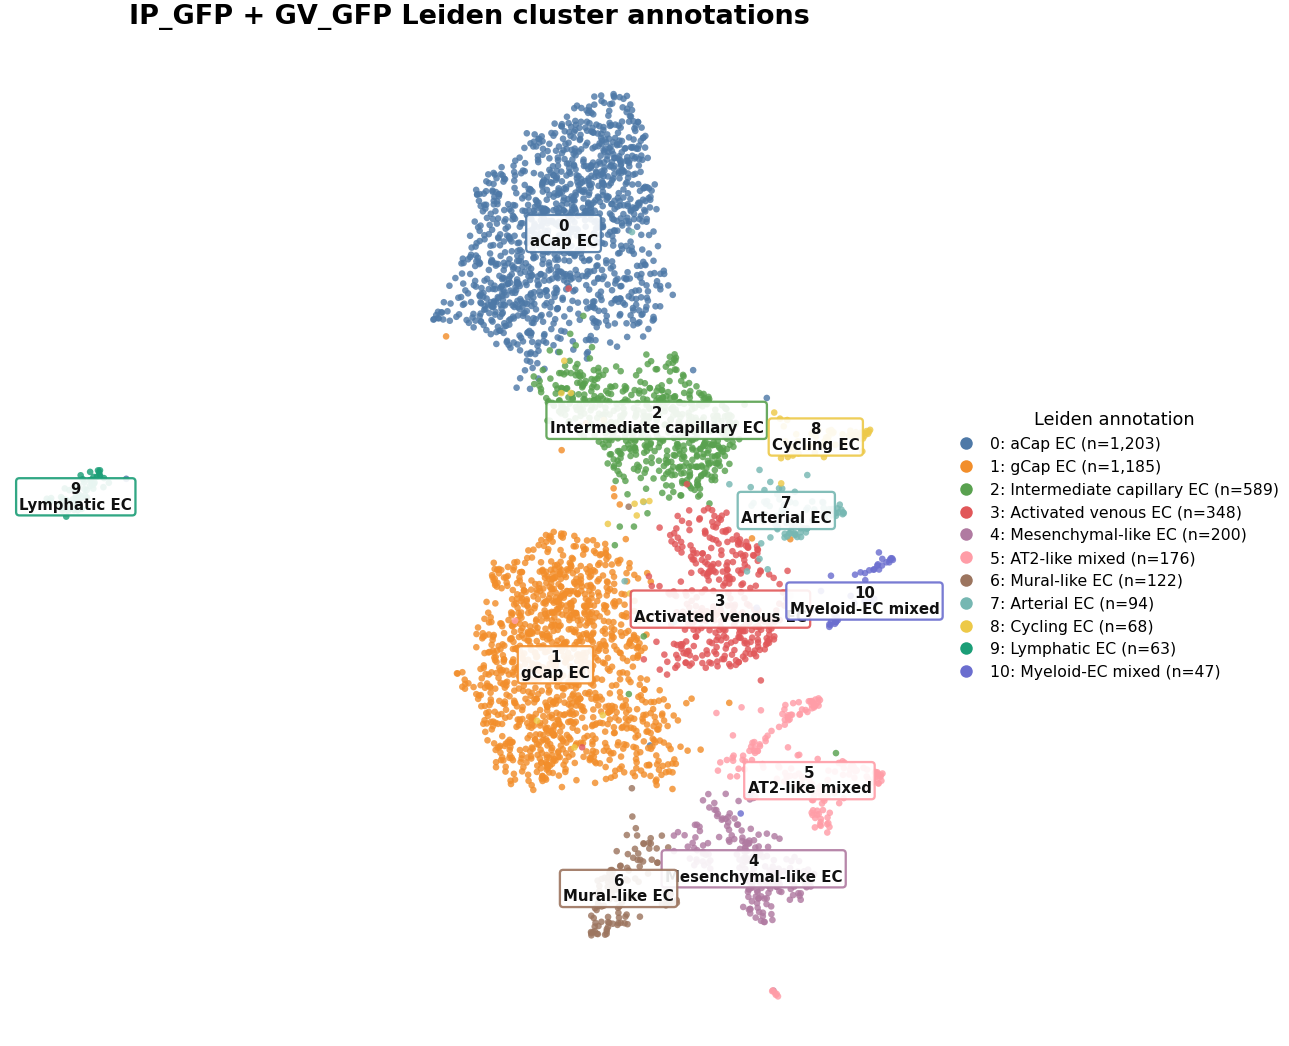

Saved annotated UMAP:
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_annotated_UMAP.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_annotated_UMAP.svg
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_annotated_UMAP.png

Saved annotation tables:
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/a

,leiden,annotation,short_label,confidence,analysis_group,recommendation,n_cells,fraction_cells,color
0,0,aCap / aerocyte capillary EC,aCap EC,high,blood_endothelial,retain,1203,0.293773,#4E79A7
1,1,gCap / general capillary EC,gCap EC,high,blood_endothelial,retain,1185,0.289377,#F28E2B
2,2,aCap-gCap intermediate capillary EC,Intermediate capillary EC,high,blood_endothelial,retain,589,0.143834,#59A14F
3,3,Activated venous endothelial cells,Activated venous EC,high,blood_endothelial,retain,348,0.084982,#E15759
4,4,Mesenchymal-like / EndMT-like endothelial cells,Mesenchymal-like EC,medium,blood_endothelial_provisional,review doublet and QC metrics,200,0.048840,#B07AA1
5,5,AT2-like epithelial mixed/doublet cluster,AT2-like mixed,medium,mixed_or_doublet,exclude from primary endothelial analysis,176,0.042979,#FF9DA7
6,6,Contractile mural-like / pericyte-like endothe...,Mural-like EC,medium-high,blood_endothelial_provisional,review doublet and QC metrics,122,0.029792,#9C755F
7,7,Arterial endothelial cells,Arterial EC,high,blood_endothelial,retain,94,0.022955,#76B7B2
8,8,Cycling endothelial cells,Cycling EC,high,blood_endothelial,retain as cell state,68,0.016606,#EDC948
9,9,Lymphatic endothelial cells,Lymphatic EC,high,lymphatic_endothelial,analyze separately when appropriate,63,0.015385,#1B9E77


In [15]:
# ================================================================
# Add provisional cell annotations and label clusters on the UMAP
# ================================================================
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

# Keep text editable in Illustrator.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["font.family"] = "DejaVu Sans"

if "leiden" not in cluster_adata.obs:
    raise KeyError("cluster_adata.obs['leiden'] is missing.")

if "X_umap" not in cluster_adata.obsm:
    raise KeyError("cluster_adata.obsm['X_umap'] is missing.")

if "CLUSTER_OUTPUT_DIR" not in globals():
    CLUSTER_OUTPUT_DIR = OUTPUT_DIR / "leiden_clustering"

CLUSTER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------
# Provisional annotations
# ----------------------------------------------------------------
CLUSTER_ANNOTATIONS = {
    "0": {
        "annotation": "aCap / aerocyte capillary EC",
        "short_label": "aCap EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain",
    },
    "1": {
        "annotation": "gCap / general capillary EC",
        "short_label": "gCap EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain",
    },
    "2": {
        "annotation": "aCap-gCap intermediate capillary EC",
        "short_label": "Intermediate capillary EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain",
    },
    "3": {
        "annotation": "Activated venous endothelial cells",
        "short_label": "Activated venous EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain",
    },
    "4": {
        "annotation": "Mesenchymal-like / EndMT-like endothelial cells",
        "short_label": "Mesenchymal-like EC",
        "confidence": "medium",
        "analysis_group": "blood_endothelial_provisional",
        "recommendation": "review doublet and QC metrics",
    },
    "5": {
        "annotation": "AT2-like epithelial mixed/doublet cluster",
        "short_label": "AT2-like mixed",
        "confidence": "medium",
        "analysis_group": "mixed_or_doublet",
        "recommendation": "exclude from primary endothelial analysis",
    },
    "6": {
        "annotation": "Contractile mural-like / pericyte-like endothelial cells",
        "short_label": "Mural-like EC",
        "confidence": "medium-high",
        "analysis_group": "blood_endothelial_provisional",
        "recommendation": "review doublet and QC metrics",
    },
    "7": {
        "annotation": "Arterial endothelial cells",
        "short_label": "Arterial EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain",
    },
    "8": {
        "annotation": "Cycling endothelial cells",
        "short_label": "Cycling EC",
        "confidence": "high",
        "analysis_group": "blood_endothelial",
        "recommendation": "retain as cell state",
    },
    "9": {
        "annotation": "Lymphatic endothelial cells",
        "short_label": "Lymphatic EC",
        "confidence": "high",
        "analysis_group": "lymphatic_endothelial",
        "recommendation": "analyze separately when appropriate",
    },
    "10": {
        "annotation": "Myeloid-endothelial mixed/doublet cluster",
        "short_label": "Myeloid-EC mixed",
        "confidence": "high",
        "analysis_group": "mixed_or_doublet",
        "recommendation": "exclude from primary endothelial analysis",
    },
}

leiden_string = cluster_adata.obs["leiden"].astype(str)

cluster_order = sorted(
    leiden_string.unique(),
    key=lambda value: int(value),
)

unknown_clusters = sorted(
    set(cluster_order).difference(CLUSTER_ANNOTATIONS),
    key=lambda value: int(value),
)

if unknown_clusters:
    raise ValueError(
        "These Leiden clusters lack annotations: "
        f"{unknown_clusters}"
    )

cluster_adata.obs["cell_annotation"] = leiden_string.map(
    {
        cluster: values["annotation"]
        for cluster, values in CLUSTER_ANNOTATIONS.items()
    }
)

cluster_adata.obs["cell_annotation_short"] = leiden_string.map(
    {
        cluster: values["short_label"]
        for cluster, values in CLUSTER_ANNOTATIONS.items()
    }
)

cluster_adata.obs["annotation_confidence"] = leiden_string.map(
    {
        cluster: values["confidence"]
        for cluster, values in CLUSTER_ANNOTATIONS.items()
    }
)

cluster_adata.obs["analysis_group"] = leiden_string.map(
    {
        cluster: values["analysis_group"]
        for cluster, values in CLUSTER_ANNOTATIONS.items()
    }
)

cluster_adata.obs["annotation_recommendation"] = leiden_string.map(
    {
        cluster: values["recommendation"]
        for cluster, values in CLUSTER_ANNOTATIONS.items()
    }
)

annotation_order = [
    CLUSTER_ANNOTATIONS[cluster]["annotation"]
    for cluster in cluster_order
]

cluster_adata.obs["cell_annotation"] = pd.Categorical(
    cluster_adata.obs["cell_annotation"],
    categories=annotation_order,
    ordered=True,
)

# ----------------------------------------------------------------
# Cluster colors
# ----------------------------------------------------------------
CLUSTER_COLORS = {
    "0": "#4E79A7",
    "1": "#F28E2B",
    "2": "#59A14F",
    "3": "#E15759",
    "4": "#B07AA1",
    "5": "#FF9DA7",
    "6": "#9C755F",
    "7": "#76B7B2",
    "8": "#EDC948",
    "9": "#1B9E77",
    "10": "#6B6ECF",
}

cluster_adata.uns["leiden_colors"] = [
    CLUSTER_COLORS[cluster]
    for cluster in cluster_order
]

# ----------------------------------------------------------------
# Calculate label positions
#
# The position is the observed cell nearest the median UMAP position,
# which usually keeps the label inside the cluster.
# ----------------------------------------------------------------
umap = np.asarray(cluster_adata.obsm["X_umap"])[:, :2]

plot_data = pd.DataFrame(
    {
        "cell_id": cluster_adata.obs_names.astype(str),
        "leiden": leiden_string.to_numpy(),
        "annotation": (
            cluster_adata.obs["cell_annotation"]
            .astype(str)
            .to_numpy()
        ),
        "short_label": (
            cluster_adata.obs["cell_annotation_short"]
            .astype(str)
            .to_numpy()
        ),
        "UMAP1": umap[:, 0],
        "UMAP2": umap[:, 1],
    }
)

label_rows = []

for cluster in cluster_order:
    current = plot_data.loc[
        plot_data["leiden"] == cluster
    ].copy()

    median_position = current[["UMAP1", "UMAP2"]].median()

    squared_distance = (
        (current["UMAP1"] - median_position["UMAP1"]) ** 2
        + (current["UMAP2"] - median_position["UMAP2"]) ** 2
    )

    nearest_cell = current.loc[squared_distance.idxmin()]

    label_rows.append(
        {
            "leiden": cluster,
            "short_label": CLUSTER_ANNOTATIONS[cluster][
                "short_label"
            ],
            "annotation": CLUSTER_ANNOTATIONS[cluster][
                "annotation"
            ],
            "UMAP1": float(nearest_cell["UMAP1"]),
            "UMAP2": float(nearest_cell["UMAP2"]),
            "n_cells": int(len(current)),
        }
    )

label_positions = pd.DataFrame(label_rows)

# Optional manual shifts after inspecting the first plot.
# Values are (horizontal shift, vertical shift) in UMAP units.
LABEL_OFFSETS = {
    # "0": (0.0, 0.0),
    # "1": (0.2, -0.1),
    # "2": (-0.1, 0.2),
}

for cluster, (x_shift, y_shift) in LABEL_OFFSETS.items():
    mask = label_positions["leiden"] == cluster
    label_positions.loc[mask, "UMAP1"] += x_shift
    label_positions.loc[mask, "UMAP2"] += y_shift

# ----------------------------------------------------------------
# Plot annotated UMAP
# ----------------------------------------------------------------
SHOW_SIDE_LEGEND = True
INCLUDE_CELL_COUNT_IN_LABEL = False

figure_width = 10.5 if SHOW_SIDE_LEGEND else 7.2

fig, ax = plt.subplots(
    figsize=(figure_width, 7.0),
    constrained_layout=True,
)

# Draw large clusters first and small clusters last.
plot_cluster_order = sorted(
    cluster_order,
    key=lambda cluster: (
        plot_data["leiden"] == cluster
    ).sum(),
    reverse=True,
)

for cluster in plot_cluster_order:
    current = plot_data.loc[
        plot_data["leiden"] == cluster
    ]

    ax.scatter(
        current["UMAP1"],
        current["UMAP2"],
        s=10,
        color=CLUSTER_COLORS[cluster],
        alpha=0.82,
        linewidths=0,
        edgecolors="none",
        rasterized=False,
        zorder=1,
    )

for row in label_positions.itertuples(index=False):
    if INCLUDE_CELL_COUNT_IN_LABEL:
        text = (
            f"{row.leiden}\n"
            f"{row.short_label}\n"
            f"n={row.n_cells:,}"
        )
    else:
        text = (
            f"{row.leiden}\n"
            f"{row.short_label}"
        )

    ax.text(
        row.UMAP1,
        row.UMAP2,
        text,
        ha="center",
        va="center",
        fontsize=7.2,
        fontweight="bold",
        color="#111111",
        linespacing=1.05,
        bbox={
            "boxstyle": "round,pad=0.22",
            "facecolor": "white",
            "edgecolor": CLUSTER_COLORS[row.leiden],
            "linewidth": 1.1,
            "alpha": 0.90,
        },
        zorder=5,
    )

ax.set_title(
    "IP_GFP + GV_GFP Leiden cluster annotations",
    fontsize=13,
    fontweight="bold",
    pad=12,
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect("equal")

for spine in ax.spines.values():
    spine.set_visible(False)

if SHOW_SIDE_LEGEND:
    cluster_counts = (
        plot_data["leiden"]
        .value_counts()
        .to_dict()
    )

    legend_handles = []

    for cluster in cluster_order:
        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="",
                markersize=6,
                markerfacecolor=CLUSTER_COLORS[cluster],
                markeredgecolor="none",
                label=(
                    f"{cluster}: "
                    f"{CLUSTER_ANNOTATIONS[cluster]['short_label']} "
                    f"(n={cluster_counts[cluster]:,})"
                ),
            )
        )

    ax.legend(
        handles=legend_handles,
        title="Leiden annotation",
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
        fontsize=7.5,
        title_fontsize=8.5,
        handletextpad=0.5,
        borderaxespad=0,
    )

# ----------------------------------------------------------------
# Save editable and preview figures
# ----------------------------------------------------------------
annotated_pdf = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotated_UMAP.pdf"
)
annotated_svg = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotated_UMAP.svg"
)
annotated_png = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotated_UMAP.png"
)

fig.savefig(annotated_pdf)
fig.savefig(annotated_svg)
fig.savefig(annotated_png, dpi=300)

plt.show()
plt.close(fig)

# ----------------------------------------------------------------
# Export annotation key and annotated cell assignments
# ----------------------------------------------------------------
annotation_key_rows = []

for cluster in cluster_order:
    values = CLUSTER_ANNOTATIONS[cluster]

    annotation_key_rows.append(
        {
            "leiden": cluster,
            "annotation": values["annotation"],
            "short_label": values["short_label"],
            "confidence": values["confidence"],
            "analysis_group": values["analysis_group"],
            "recommendation": values["recommendation"],
            "n_cells": int(
                (leiden_string == cluster).sum()
            ),
            "fraction_cells": float(
                (leiden_string == cluster).mean()
            ),
            "color": CLUSTER_COLORS[cluster],
        }
    )

annotation_key = pd.DataFrame(annotation_key_rows)

annotation_key_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotation_key.csv"
)

annotation_key.to_csv(
    annotation_key_path,
    index=False,
)

annotated_assignments = (
    cluster_adata.obs[
        [
            "leiden",
            "cell_annotation",
            "cell_annotation_short",
            "annotation_confidence",
            "analysis_group",
            "annotation_recommendation",
        ]
    ]
    .copy()
    .reset_index()
    .rename(columns={"index": "cell_id"})
)

annotated_assignments_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotated_cell_assignments.csv.gz"
)

annotated_assignments.to_csv(
    annotated_assignments_path,
    index=False,
    compression="gzip",
)

label_positions_path = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotation_label_positions.csv"
)

label_positions.to_csv(
    label_positions_path,
    index=False,
)

# Add annotations to the existing plotting table, when present.
if "cell_table" in globals():
    annotation_by_cell = pd.Series(
        cluster_adata.obs["cell_annotation"]
        .astype(str)
        .to_numpy(),
        index=cluster_adata.obs_names.astype(str),
    )

    leiden_by_cell = pd.Series(
        leiden_string.to_numpy(),
        index=cluster_adata.obs_names.astype(str),
    )

    cell_table["leiden"] = (
        cell_table["cell_id"]
        .astype(str)
        .map(leiden_by_cell)
    )

    cell_table["cell_annotation"] = (
        cell_table["cell_id"]
        .astype(str)
        .map(annotation_by_cell)
    )

print("Saved annotated UMAP:")
print(annotated_pdf)
print(annotated_svg)
print(annotated_png)

print("\nSaved annotation tables:")
print(annotation_key_path)
print(annotated_assignments_path)
print(label_positions_path)

display(annotation_key)

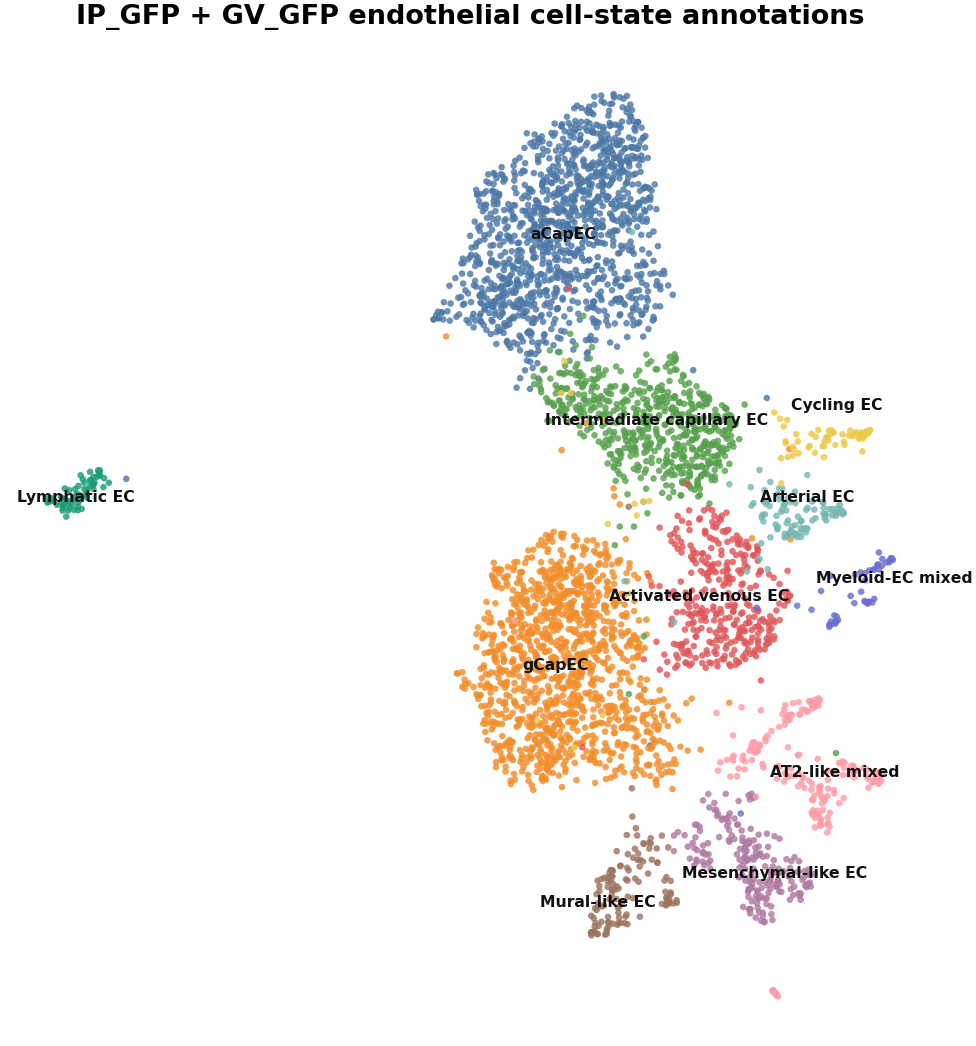

/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_annotation_plain_text.pdf
/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/selected_program_umap/continuous_usage_and_Cdh5/leiden_clustering/IP_GV_leiden_annotation_plain_text.svg


In [16]:
# ================================================================
# Plain-text Leiden annotations: no boxes and no cluster numbers
# ================================================================
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SHORT_LABELS = {
    "0": "aCapEC",
    "1": "gCapEC",
    "2": "Intermediate capillary EC",
    "3": "Activated venous EC",
    "4": "Mesenchymal-like EC",
    "5": "AT2-like mixed",
    "6": "Mural-like EC",
    "7": "Arterial EC",
    "8": "Cycling EC",
    "9": "Lymphatic EC",
    "10": "Myeloid-EC mixed",
}

CLUSTER_COLORS = {
    "0": "#4E79A7",
    "1": "#F28E2B",
    "2": "#59A14F",
    "3": "#E15759",
    "4": "#B07AA1",
    "5": "#FF9DA7",
    "6": "#9C755F",
    "7": "#76B7B2",
    "8": "#EDC948",
    "9": "#1B9E77",
    "10": "#6B6ECF",
}

leiden = cluster_adata.obs["leiden"].astype(str)

cluster_adata.obs["cell_annotation_short"] = leiden.map(
    SHORT_LABELS
)

umap = np.asarray(cluster_adata.obsm["X_umap"])[:, :2]

plot_data = pd.DataFrame(
    {
        "cell_id": cluster_adata.obs_names.astype(str),
        "leiden": leiden.to_numpy(),
        "UMAP1": umap[:, 0],
        "UMAP2": umap[:, 1],
    }
)

cluster_order = sorted(
    plot_data["leiden"].unique(),
    key=int,
)

# Put labels near the median location of each cluster.
label_rows = []

for cluster in cluster_order:
    current = plot_data.loc[
        plot_data["leiden"] == cluster
    ]

    median_x = float(current["UMAP1"].median())
    median_y = float(current["UMAP2"].median())

    distance = (
        (current["UMAP1"] - median_x) ** 2
        + (current["UMAP2"] - median_y) ** 2
    )

    nearest = current.loc[distance.idxmin()]

    label_rows.append(
        {
            "leiden": cluster,
            "label": SHORT_LABELS[cluster],
            "UMAP1": float(nearest["UMAP1"]),
            "UMAP2": float(nearest["UMAP2"]),
        }
    )

label_positions = pd.DataFrame(label_rows)

# Optional offsets as fractions of the total UMAP width/height.
# Adjust these when labels overlap.
x_range = float(np.ptp(umap[:, 0]))
y_range = float(np.ptp(umap[:, 1]))

LABEL_OFFSETS = {
    "3": (-0.025, 0.015),
    "4": (0.025, -0.005),
    "5": (0.030, 0.010),
    "6": (-0.025, -0.015),
    "7": (0.025, 0.015),
    "8": (0.025, 0.035),
    "10": (0.035, 0.025),
}

for cluster, (x_fraction, y_fraction) in LABEL_OFFSETS.items():
    mask = label_positions["leiden"] == cluster

    label_positions.loc[mask, "UMAP1"] += (
        x_fraction * x_range
    )
    label_positions.loc[mask, "UMAP2"] += (
        y_fraction * y_range
    )

SHOW_SIDE_LEGEND = False

fig, ax = plt.subplots(
    figsize=(9.0 if SHOW_SIDE_LEGEND else 7.2, 7.0),
    constrained_layout=True,
)

# Plot large clusters first and small clusters last.
plot_order = sorted(
    cluster_order,
    key=lambda cluster: (
        plot_data["leiden"] == cluster
    ).sum(),
    reverse=True,
)

for cluster in plot_order:
    current = plot_data.loc[
        plot_data["leiden"] == cluster
    ]

    ax.scatter(
        current["UMAP1"],
        current["UMAP2"],
        s=10,
        color=CLUSTER_COLORS[cluster],
        alpha=0.82,
        linewidths=0,
        edgecolors="none",
        rasterized=False,
        zorder=1,
    )

# Plain text only: no cluster number and no bounding box.
for row in label_positions.itertuples(index=False):
    ax.text(
        row.UMAP1,
        row.UMAP2,
        row.label,
        ha="center",
        va="center",
        fontsize=7.5,
        fontweight="bold",
        color="#111111",
        zorder=5,
    )

ax.set_title(
    "IP_GFP + GV_GFP endothelial cell-state annotations",
    fontsize=13,
    fontweight="bold",
    pad=12,
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect("equal")

for spine in ax.spines.values():
    spine.set_visible(False)

# Optional side legend, also without cluster numbers.
if SHOW_SIDE_LEGEND:
    cluster_counts = (
        plot_data["leiden"]
        .value_counts()
        .to_dict()
    )

    handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markersize=6,
            markerfacecolor=CLUSTER_COLORS[cluster],
            markeredgecolor="none",
            label=(
                f"{SHORT_LABELS[cluster]} "
                f"(n={cluster_counts[cluster]:,})"
            ),
        )
        for cluster in cluster_order
    ]

    ax.legend(
        handles=handles,
        title="Cell annotation",
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
        fontsize=7.5,
        title_fontsize=8.5,
    )

plain_pdf = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotation_plain_text.pdf"
)
plain_svg = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotation_plain_text.svg"
)
plain_png = (
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_annotation_plain_text.png"
)

fig.savefig(plain_pdf)
fig.savefig(plain_svg)
fig.savefig(plain_png, dpi=300)

plt.show()
plt.close(fig)

label_positions.to_csv(
    CLUSTER_OUTPUT_DIR
    / "IP_GV_leiden_plain_text_label_positions.csv",
    index=False,
)

print(plain_pdf)
print(plain_svg)